# 0. Подготовка проекта

In [271]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn

RANDOM_STATE = 42
DATA_PATH = Path('data/Dataset.xlsx')

print(sys.version)
print('pandas:',pd.__version__)
print('scikit-learn:',sklearn.__version__)

3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
pandas: 3.0.6
scikit-learn: 1.9.1


# 1. Постановка задачи

В рассматриваемом датасете каждый объект наблюдения представляет собой попытку аутентификации. Необходимо определить, является ли конкретная попытка входа подозрительным событием в системе. Результат оценки используется специалистом по информационной безопасности, который на его основе может принять соответствующие меры реагирования, например дополнительно проверить попытку входа или ограничить доступ.

## 1.1. Объект анализа

Объект анализа – **одна попытка аутентификации**

Чтобы это доказать, выведем сколько раз встречается каждый пользователь.

In [272]:
df = pd.read_excel(DATA_PATH, sheet_name="Data")
df["user_id"].value_counts()

user_id
usr_062    24
usr_025    21
usr_082    19
usr_060    17
usr_113    17
           ..
usr_069     6
usr_048     6
usr_040     6
usr_012     5
usr_031     4
Name: count, Length: 120, dtype: int64

По выводу ясно, что каждый пользователь встречается один или более раз. Теперь посмотрим, как меняются данные у одного из пользователей.

In [273]:
df[df["user_id"] == "usr_012"]

,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
70,evt_000693,2026-01-29 16:05:52,usr_012,HR,192.0.2.166,DE,tablet,iOS,Safari,password,...,2,62.0,2271,132,1,0,0,benign,22,0
699,evt_000151,2026-02-21 12:10:53,usr_012,HR,203.0.113.88,DE,tablet,iOS,Safari,password,...,3,0.4,2294,155,1,0,0,benign,51,0
716,evt_000442,2026-02-15 11:46:18,usr_012,HR,203.0.113.88,DE,tablet,iOS,Safari,password,...,4,NaN,2288,149,1,0,0,benign,60,0
940,evt_000166,2026-03-05 17:43:01,usr_012,HR,203.0.113.88,DE,tablet,iOS,Safari,password,...,2,19.1,2306,167,1,0,0,benign,3,0
1302,evt_000387,2026-01-22 15:57:07,usr_012,HR,203.0.113.88,DE,tablet,iOS,Safari,password,...,3,4.8,2264,125,1,0,0,benign,61,0


Как можно заметить, для usr_012 меняются некоторые данные. Разное время входа в систему, а также различные IP-адреса и т.д.

По полученным данным можно сделать вывод, что одна строка - это отдельное событие аутентификации, а не пользователя целиком.

## 1.2. Целевая переменная

is_suspicious - целевая переменная, т.е. она является результатом, который мы хотим предсказывать. По остальным признакам X будет определяться значение is_suspicious.

Посмотрим какие классы имеются у is_suspicious:

In [274]:
df["is_suspicious"].value_counts()

is_suspicious
0    1301
1     129
Name: count, dtype: int64

У is_suspicious два класса: 1 и 0. Из исходных данных известно, что 1 соответсвтует подозрительному событию, 0 нормальному событию.

## 1.3. Паспорт датасета

**Происхождение:** учебный синтетический набор данных, предоставленный для выполнения лабораторной работы.

**Дата получения:** 25.09.2026

**Исходный размер:** 1430 строк x 23 столбца

In [275]:
df.shape

(1430, 23)

**Ограничения:** так как данные являются синтетическими (искусственными), они не отражают полностью особенности реальных событий информационной безопасности. Распределение признаков и сценарии атак могут отличаться от реальных данных, поэтому результаты анализа нельзя переносить на настоящую инфраструктуру.

### 1.4. Таблица признаков

Посморим фактические типы:

In [276]:
df.dtypes

event_id                      str
timestamp                     str
user_id                       str
department                    str
source_ip                     str
country                       str
device_type                   str
os_family                     str
browser_family                str
auth_method                   str
hour                        int64
is_weekend                  int64
failed_attempts_24h         int64
login_velocity_1h           int64
distance_from_usual_km    float64
account_age_days            int64
password_age_days          object
known_device                int64
new_country                 int64
vpn_used                    int64
analyst_verdict               str
analyst_risk_score          int64
is_suspicious               int64
dtype: object

Составим таблицу:

| Название столбца         | Смысл                                              | Фактический тип | Ожидаемый тип            | Допустимые значения              | Момент доступности           | Решение об использовании         |
| ------------------------ | -------------------------------------------------- | --------------- | ------------------------ | -------------------------------- | ---------------------------- | -------------------------------- |
| `event_id`               | Уникальный идентификатор события                   | `str`           | строковый                | уникальные ID                    | В момент события             | Не использовать                  |
| `timestamp`              | Дата и время события                               | `str`           | datetime                 | корректные дата и время          | В момент события             | Использовать                     |
| `user_id`                | Идентификатор пользователя                         | `str`           | категориальный           | ID пользователей                 | В момент события               | Не использовать как X/Использовать для группировки при разбиении данных                     |
| `department`             | Подразделение пользователя                         | `str`           | категориальный           | значения подразделений           | В момент события            | Использовать                     |
| `source_ip`              | IP-адрес источника входа                           | `str`           | строковый | корректные IP-адреса             | В момент события               | Использовать                     |
| `country`                | Страна, связанная с попыткой входа                 | `str`           | категориальный           | названия стран                   | В момент события               | Использовать                     |
| `device_type`            | Тип устройства                                     | `str`           | категориальный           | значения типов устройств         | В момент события               | Использовать                     |
| `os_family`              | Семейство операционной системы                     | `str`           | категориальный           | значения ОС                      | В момент события               | Использовать                     |
| `browser_family`         | Семейство браузера                                 | `str`           | категориальный           | значения браузеров               | В момент события               | Использовать                     |
| `auth_method`            | Метод аутентификации                               | `str`           | категориальный           | допустимые методы аутентификации | В момент события               | Использовать                     |
| `hour`                   | Час события                                        | `int64`         | целое число              | 0-23                             | В момент события             | Использовать                     |
| `is_weekend`             | Признак выходного дня                              | `int64`         | бинарный                 | 0,1                             | В момент события             | Использовать                     |
| `failed_attempts_24h`    | Количество неудачных попыток за последние 24 часа  | `int64`         | целое число              | ≥ 0                              | В момент события           | Использовать                     |
| `login_velocity_1h`      | Интенсивность входов за последний час              | `int64`         | целое число              | ≥ 0                              | В момент события           | Использовать                     |
| `distance_from_usual_km` | Расстояние от обычного места входа                 | `float64`       | вещественное число       | ≥ 0                              | В момент события               | Использовать                     |
| `account_age_days`       | Возраст учётной записи в днях                      | `int64`         | целое число              | ≥ 0                              | До события                     | Использовать|
| `password_age_days`      | Возраст пароля в днях                              | `object`        | целое число              | ≥ 0                              | До события                     | Использовать |
| `known_device`           | Признак известного устройства                      | `int64`         | бинарный                 | 0,1                             | В момент события               | Использовать                     |
| `new_country`            | Признак новой страны для пользователя              | `int64`         | бинарный                 | 0,1                             | В момент события               | Использовать                     |
| `vpn_used`               | Признак использования VPN                          | `int64`         | бинарный                 | 0,1                             | В момент события               | Использовать                     |
| `analyst_verdict`        | Решение аналитика по событию                       | `str`           | категориальный           | значения вердиктов               | После анализа события        | Не использовать                  |
| `analyst_risk_score`     | Оценка риска аналитиком                            | `int64`         | целое число              | допустимый диапазон оценки       | После анализа события        | Не использовать                  |
| `is_suspicious`          | Целевая переменная: подозрительное событие или нет | `int64`         | бинарный                 | 0,1                             | После определения результата | **y, не использовать как X**     |

analyst_verdict и analyst_risk_score являются результатами анализа событий и поэтому не могут использоваться для обучения. Эти данные дают модели ответ, чем фактически является события.

# 2. Инвентаризация

Загрузка листа "Данные" файла .xlsx была выполнена в пункте 1.

## 2.1. Анализ структуры и размера датасета

Выведем первые строки датасета:

In [277]:
df.head()

,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
0,evt_001370,2026-03-12 20:27:57,usr_046,Operations,203.0.113.178,SE,mobile,Android,Chrome,password,...,1,39.4,871,229,0,0,0,benign,65,0
1,evt_000493,2026-01-06 00:17:20,usr_068,Sales,203.0.113.132,RU,mobile,Android,Chrome,password,...,5,16.9,2383,11,1,0,0,benign,43,0
2,evt_000433,2026-01-27 17:57:11,usr_033,SOC,192.0.2.185,PL,laptop,Windows,Chrome,password,...,5,28.8,795,258,1,0,0,benign,50,0
3,evt_001361,2026-03-10 16:30:25,usr_085,Sales,192.0.2.91,NO,mobile,Android,Chrome,otp,...,3,26.1,1186,184,1,0,0,benign,40,0
4,evt_000791,2026-02-10 05:26:56,usr_092,R&D,203.0.113.190,DE,laptop,Windows,Chrome,fido2,...,6,86.0,784,182,1,0,0,benign,7,0


Выведем последние строки датасета:

In [278]:
df.tail()

,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
1425,evt_000907,2026-03-09 00:01:20,usr_065,Operations,203.0.113.93,PL,tablet,iOS,Safari,push,...,2,49.8,3245,79,1,0,0,benign,15,0
1426,evt_001094,2026-01-17 09:15:30,usr_051,HR,192.0.2.165,RU,tablet,iOS,Safari,password,...,2,64.2,1803,239,1,0,0,benign,46,0
1427,evt_001253,2026-01-25 00:38:56,usr_061,R&D,198.51.100.128,RU,desktop,Windows,Chrome,otp,...,13,1088.3,2917,177,1,1,0,confirmed_threat,78,1
1428,evt_000743,2026-02-23 22:19:53,usr_043,HR,192.0.2.51,US,laptop,Windows,Edge,otp,...,5,14.4,1495,257,1,0,0,benign,31,0
1429,evt_000581,2026-02-14 19:29:43,usr_019,Finance,198.51.100.3,NL,laptop,Windows,Chrome,password,...,2,73.4,2915,unknown,1,0,0,benign,24,0


Посмотрим размер таблицы:

In [279]:
df.shape

(1430, 23)

Посмотрим названия столбцов:

In [280]:
df.columns

Index(['event_id', 'timestamp', 'user_id', 'department', 'source_ip',
       'country', 'device_type', 'os_family', 'browser_family', 'auth_method',
       'hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h',
       'distance_from_usual_km', 'account_age_days', 'password_age_days',
       'known_device', 'new_country', 'vpn_used', 'analyst_verdict',
       'analyst_risk_score', 'is_suspicious'],
      dtype='str')

Посмотрим типы данных и объём памяти:

In [281]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   event_id                1430 non-null   str    
 1   timestamp               1430 non-null   str    
 2   user_id                 1430 non-null   str    
 3   department              1416 non-null   str    
 4   source_ip               1430 non-null   str    
 5   country                 1430 non-null   str    
 6   device_type             1430 non-null   str    
 7   os_family               1430 non-null   str    
 8   browser_family          1400 non-null   str    
 9   auth_method             1430 non-null   str    
 10  hour                    1430 non-null   int64  
 11  is_weekend              1430 non-null   int64  
 12  failed_attempts_24h     1430 non-null   int64  
 13  login_velocity_1h       1430 non-null   int64  
 14  distance_from_usual_km  1398 non-null   float64
 15

## 2.2. Проверка объектов и целевого столбца

Проверим, что число строк соответсвует числу объектов:

In [282]:
df.shape[0]

1430

Полученное число строк соответствует числу объектов, так как каждая строка датасета представляет одно событие.

Проверим, что целевой столбец присутствует один раз:

In [283]:
list(df.columns).count("is_suspicious")

1

## 2.3. Описательная статистика признаков

Для числовых признаков выведем описательные статистики:

In [284]:
df.describe()

,hour,is_weekend,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,account_age_days,known_device,new_country,vpn_used,analyst_risk_score,is_suspicious
count,1430.000000,1430.000000,1430.000000,1430.000000,1398.000000,1430.000000,1430.000000,1430.000000,1430.000000,1430.000000,1430.000000
mean,11.731469,0.280420,1.897902,3.197902,376.536409,1637.660140,0.911189,0.044755,0.118182,40.848951,0.090210
std,7.113637,0.449361,37.336751,2.222254,1853.187377,921.062124,0.284571,0.206838,0.322936,23.968772,0.286582
min,0.000000,0.000000,-1.000000,1.000000,-25.000000,-7.000000,0.000000,0.000000,0.000000,3.000000,0.000000
25%,6.000000,0.000000,0.000000,2.000000,15.700000,839.750000,1.000000,0.000000,0.000000,20.000000,0.000000
50%,12.000000,0.000000,0.000000,3.000000,31.350000,1656.500000,1.000000,0.000000,0.000000,40.000000,0.000000
75%,18.000000,1.000000,1.000000,4.000000,56.275000,2365.500000,1.000000,0.000000,0.000000,59.000000,0.000000
max,23.000000,1.000000,999.000000,18.000000,20000.000000,3266.000000,1.000000,1.000000,1.000000,99.000000,1.000000


Для категориальных признаков выведем число уникальных значений и наиболее частые категории:

In [285]:
categorical_columns = df.select_dtypes(include="str").columns # выбираем столбцы со строковым типом данных

for col in categorical_columns:
    print(f"\n- {col} -")
    print("Unique values:", df[col].nunique()) # кол-во уникальных значений
    print("Most frequent values:")
    print(df[col].value_counts().head())


- event_id -
Unique values: 1412
Most frequent values:
event_id
evt_000433    2
evt_000847    2
evt_001063    2
evt_001315    2
evt_000107    2
Name: count, dtype: int64

- timestamp -
Unique values: 1412
Most frequent values:
timestamp
2026-01-27 17:57:11    2
2026-02-16 18:53:44    2
2026-01-23 04:25:22    2
2026-02-21 02:47:56    2
2026-01-08 01:00:54    2
Name: count, dtype: int64

- user_id -
Unique values: 120
Most frequent values:
user_id
usr_062    24
usr_025    21
usr_082    19
usr_060    17
usr_113    17
Name: count, dtype: int64

- department -
Unique values: 8
Most frequent values:
department
SOC           269
R&D           248
HR            196
Operations    179
IT            176
Name: count, dtype: int64

- source_ip -
Unique values: 320
Most frequent values:
source_ip
198.51.100.81    17
192.0.2.28       14
192.0.2.242      14
192.0.2.95       13
198.51.100.60    13
Name: count, dtype: int64

- country -
Unique values: 9
Most frequent values:
country
NO    393
DE    268

Сохраним исходное число строк и столбцов в переменные:

In [286]:
orig_rows, orig_cols = df.shape
print(orig_rows, orig_cols)

1430 23


# 3. Проверка типов и допустимых значений

## 3.1. Проверка типов и форматов данных

Выведем фактические типы каждого столбца:

In [287]:
df.dtypes

event_id                      str
timestamp                     str
user_id                       str
department                    str
source_ip                     str
country                       str
device_type                   str
os_family                     str
browser_family                str
auth_method                   str
hour                        int64
is_weekend                  int64
failed_attempts_24h         int64
login_velocity_1h           int64
distance_from_usual_km    float64
account_age_days            int64
password_age_days          object
known_device                int64
new_country                 int64
vpn_used                    int64
analyst_verdict               str
analyst_risk_score          int64
is_suspicious               int64
dtype: object

Основываясь на таблице из пункта 1.4 можно сделать вывод, что фактический тип столбцов password_age_days и timestamp не соответствует их смыслу:
- password_age_days в результате имеет тип object, но столбец соответствует количеству дней и потому должен быть тип int;
- timestamp имеет тип str, но ожидаемый тип datetime.

Посмотрим, почему для password_age_days тип определяется как object:

In [288]:
df["password_age_days"].unique()

array([229, 11, 258, 184, 182, 114, 211, 95, 103, 328, 319, 324, 291, 272,
       206, 87, 298, 256, 73, 198, 281, 343, 380, 242, 239, 235, 335, 267,
       107, 117, 219, 332, 168, 310, 204, 176, 193, 270, 260, 263, 118,
       334, 162, 143, 311, 352, 308, 269, 216, 398, 317, 275, 222, 158,
       94, 227, 364, 188, 252, 224, 234, 359, 132, 90, 257, 106, 301, 152,
       104, 189, 215, 326, 101, 194, 246, 323, 146, 147, 331, 283, 296,
       341, 49, 315, 322, 191, 299, 226, 231, 240, 71, 273, 141, 91, 100,
       284, 247, 126, 18, 383, 261, 228, 254, 115, 236, 321, 243, 401,
       309, 294, 83, 318, 274, 277, 199, 109, 185, 119, 233, 213, 369, 75,
       336, 177, 238, 202, 253, 248, 165, 85, 164, 180, 135, 183, 137, 19,
       265, 61, 192, 244, 133, 230, 'unknown', 69, 196, 339, 249, 327, 79,
       89, 342, 178, 289, 330, 320, 279, 208, 150, 130, 360, 286, 218,
       124, 313, 98, 108, 163, 41, 212, 149, 292, 99, 393, 278, 70, 223,
       285, 302, 355, 266, 237, 145, 316, 306

В списке можно заметить строковое значение 'unknown', по этой причине для password_age_days не определялся тип int.

Теперь найдем смешанные форматы дат. Для этого сначала посмотрим формат, который встречается в датасете:

In [289]:
df["timestamp"]

0       2026-03-12 20:27:57
1       2026-01-06 00:17:20
2       2026-01-27 17:57:11
3       2026-03-10 16:30:25
4       2026-02-10 05:26:56
               ...         
1425    2026-03-09 00:01:20
1426    2026-01-17 09:15:30
1427    2026-01-25 00:38:56
1428    2026-02-23 22:19:53
1429    2026-02-14 19:29:43
Name: timestamp, Length: 1430, dtype: str

В результате преобладает формат 'YYYY-MM-DD HH:MM:SS', поэтому его возьмем за основу.

Напишем программу, которая выведет неподходящие под шаблон форматы, а также даты, которые не существуют.

In [290]:
parsed = pd.to_datetime( # преобразуем данные по заданному формату
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S", # заданный шаблон
    errors="coerce" # если формат не подходит, то ставим NaT
)

display( # показать полученный результат в виде таблицы
    df.loc[ # выбираем конкретные строки и столбцы из таблицы df
        parsed.isna(), # выбираем только те строки где стоит NaT
        ["event_id", "timestamp"] # отображаемые столбцы
        ]
)

,event_id,timestamp
418,evt_000920,not_recorded
422,evt_001299,17.03.2026 13:45
727,evt_001047,2026/03/12 25:61
1034,evt_000098,2026-02-30 09:15:00


Получилось 4 результата: значение 'not_recorded', 1 отличный от основного формата, несуществующее время 25:61 и 30 февраля.

Далее найдем категориальные признаки с ошибочными вариантами написания:

In [291]:
categorical_columns = [
    "department",
    "country",
    "device_type",
    "os_family",
    "browser_family",
    "auth_method",
    "analyst_verdict"
]

for col in categorical_columns:
    print("\n")
    print(df[col].value_counts())



department
SOC           269
R&D           248
HR            196
Operations    179
IT            176
Sales         174
Finance       166
unknown         8
Name: count, dtype: int64


country
NO    393
DE    268
SE    257
NL    188
US    135
PL     95
RU     80
BR      8
CN      6
Name: count, dtype: int64


device_type
mobile     491
tablet     334
laptop     329
desktop    276
Name: count, dtype: int64


os_family
Android    464
Windows    409
iOS        361
macOS      123
Linux       73
Name: count, dtype: int64


browser_family
Chrome     793
Safari     263
Edge       182
Firefox    152
-           10
Name: count, dtype: int64


auth_method
password    571
push        372
otp         330
fido2       157
Name: count, dtype: int64


analyst_verdict
benign              1301
confirmed_threat     129
Name: count, dtype: int64


По результату можно сделать вывод, что категориальных признаков с ошибочными вариантами написания не было найдено.

## 3.2. Предметные ограничения

Необходимо сформулировать предметные ограничения для счетчиков, расстояний, возраста учётной записи и бинарных признаков.

В таблице из пункта 1.4 прописаны допустимые значения. Проверим, нарушают ли какие то строки эти ограничения.

Под проверку попадают следующие столбцы:
- failed_attempts_24h
- login_velocity_1h
- distance_from_usual_km
- account_age_days
- password_age_days
- hour
- is_weekend
- known_device
- new_country
- vpn_used
- is_suspicious

Проверим для hour:

In [292]:
df.loc[~df["hour"].between(0, 23), ["event_id", "hour"]]

,event_id,hour


Все значения в допустимом диапазоне.

Проверим для бинарных признаков:

In [293]:
columns = [
    "is_weekend",
    "known_device",
    "new_country",
    "vpn_used",
    "is_suspicious"
]

for col in columns:
    print("\n")
    display(df.loc[~df[col].isin([0, 1]), ["event_id", col]])

,event_id,is_weekend


,event_id,known_device


,event_id,new_country


,event_id,vpn_used


,event_id,is_suspicious


По результату видно, что все значения в допустимом диапазоне.

Проверим счётчики, расстояние и возраст аккаунта:

In [294]:
cols = ["failed_attempts_24h", 
        "login_velocity_1h", 
        "distance_from_usual_km", 
        "account_age_days"
]

for col in cols:
    print("\n")
    display(df.loc[df[col] < 0, ["event_id", col]])

,event_id,failed_attempts_24h
407,evt_000829,-1
877,evt_000066,-1
1106,evt_000781,-1


,event_id,login_velocity_1h


,event_id,distance_from_usual_km
379,evt_000186,-25.0
480,evt_000594,-25.0
1027,evt_000804,-25.0
1192,evt_000440,-25.0


,event_id,account_age_days
436,evt_000067,-7
843,evt_000024,-7
1171,evt_000925,-7


По результату видно, что были найдены технические ошибки. Отрицательные значения невозможны для данных признаков, поэтому их необходимо исправить.

Далее проверим, что расстояние не превышает максимальное возможное (20004 км):

In [295]:
display(df.loc[df["distance_from_usual_km"] > 20004, ["event_id", "distance_from_usual_km"]])

,event_id,distance_from_usual_km


Такие строки не нашлись.

Также проверим, существуют ли строки, где возраст пароля больше возраста аккаунта:

In [296]:
password_age = pd.to_numeric(
    df["password_age_days"].replace("unknown", np.nan),
    errors="coerce"
)

mask = password_age > df["account_age_days"]

print("Total:", mask.sum())

Total: 93


Были найдены 93 строки. Это невозможно и потому подлежит замене.

## 3.3. Исправление

Начнем с исправления отрицательных значений. Так как мы точно не знаем каким образом они получилось отрицательными, то заменим значения на NaN:

In [297]:
cols = ["failed_attempts_24h", 
        "distance_from_usual_km", 
        "account_age_days"
]

k = 0

for col in cols:
    k += int((df[col] < 0).sum())
    print(f"{col}: {(df[col] < 0).sum()} values replaced")
    df.loc[df[col] < 0, col] = np.nan

print(f"Total: {k}")

failed_attempts_24h: 3 values replaced
distance_from_usual_km: 4 values replaced
account_age_days: 3 values replaced
Total: 10


Как видно по результату, всего в сумме было выполнено 10 замен.

Далее выполним исправления для дат. Из пункта 3.1 известно, что есть 3 некорректные строки и одна строка с отличным от основного форматом.

Исправим 3 некорректные строки на NaT и изменим формат строки c другим форматом:

In [298]:
# Преобразуем даты стандартного формата
parsed = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S", # шаблон стандартного формата
    errors="coerce" # если дата не подходит, то записываем NaT вместо ошибки
)

# Находим даты, записанные в другом формате
mask = df["timestamp"].str.match( # проверяем, соответствует ли текст заданному шаблону
    r"^\d{2}\.\d{2}\.\d{4} \d{2}:\d{2}$", # r".." - правило поиска текста. Отличный от основного шаблон: DD.MM.YYYY HH:MM
    na=False # если значение пустое, значит оно не соответствует шаблону, т.е. False
)

# Меняем строку с отличным форматом от основного
parsed.loc[mask] = pd.to_datetime( # записать результат в переменную parsed, но только в те строки, которые отмечены mask
    df.loc[mask, "timestamp"],
    format="%d.%m.%Y %H:%M",
    errors="coerce" # NaT вместо ошибки
)

df["timestamp"] = parsed

print("NaT count:", df["timestamp"].isna().sum())

# Cтроки с NaT
display(
    df.loc[
        df["timestamp"].isna(),
        ["event_id", "timestamp"]
    ]
)

NaT count: 3


,event_id,timestamp
418,evt_000920,NaT
727,evt_001047,NaT
1034,evt_000098,NaT


Таким образом, были исправлены 3 некорректные строки и изменен формат строки с другим форматом.

Заменим значения возраста пароля, где он превышает возраст аккаунта на NaN:

In [299]:
password_age = pd.to_numeric(
    df["password_age_days"].replace("unknown", np.nan), # временно избавимся от unknown
    errors="coerce"
)

account_age = pd.to_numeric(
    df["account_age_days"],
    errors="coerce"
)

mask = password_age > account_age

df.loc[mask, "password_age_days"] = np.nan

print(f"Total: {mask.sum()}")

Total: 90


Заменены 90 строки.

# 4. Анализ пропусков

## 4.1. Расчёт числа и доли пропусков

Рассчитаем число и долю пропусков для каждого столбца:

In [300]:
# Считаем количество пропусков в каждом столбце
missing_count = df.isna().sum()

# Считаем долю пропусков в процентах
missing_percent = df.isna().mean() * 100

# Собираем результаты в таблицу
missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

# Оставляем только столбцы с пропусками
missing_table = missing_table[missing_table["missing_count"] > 0]

# Сортируем по убыванию доли пропусков
missing_table = missing_table.sort_values(
    by="missing_percent",
    ascending=False
)

display(missing_table.round(2))


,missing_count,missing_percent
password_age_days,90,6.29
distance_from_usual_km,36,2.52
browser_family,30,2.10
department,14,0.98
timestamp,3,0.21
failed_attempts_24h,3,0.21
account_age_days,3,0.21


## 4.2. Скрытые значения

Найдем скрытые значения:

In [301]:
# Возможные обозначения пропусков
markers = [
    "?", "unknown", "-", "not_recorded",
    "n/a", "null", "none", "missing",
    "not available", "", "0"
]

# Проверяем текстовые столбцы
for col in df.select_dtypes(include=["object", "str"]).columns:
    values = df[col].astype("string").str.strip().str.lower()

    for marker in markers:
        count = (values == marker).sum()

        if count > 0:
            print(f"{col}: '{marker}' — {count} values")

department: 'unknown' — 8 values
browser_family: '-' — 10 values
password_age_days: 'unknown' — 9 values


Нашлись 3 признака со скрытыми пропусками.

## 4.3. Решение проблемных признаков

В итоге получился следующий список признаков:
- distance_from_usual_km
- browser_family
- department
- timestamp
- failed_attempts_24h
- account_age_days
- password_age_days

Первым делом преобразуем скрытые значения 'unknown' и '-' в настоящие пропуски:

In [302]:
# Убираем пробелы и приводим текст к нижнему регистру
df["department"] = df["department"].apply(
    lambda x: x.strip().lower() if isinstance(x, str) else x
)

df["password_age_days"] = df["password_age_days"].apply(
    lambda x: x.strip().lower() if isinstance(x, str) else x
)

# Заменяем маркеры пропусков
df["browser_family"] = df["browser_family"].replace(
    r"^\s*-\s*$", np.nan, regex=True
)

df["department"] = df["department"].replace("unknown", np.nan)

df["password_age_days"] = df["password_age_days"].replace(
    "unknown", np.nan
)

# Преобразуем возраст пароля в число
df["password_age_days"] = pd.to_numeric(
    df["password_age_days"], errors="coerce"
)

print(df[[
    "browser_family",
    "department",
    "password_age_days"
]].isna().sum())

browser_family       40
department           22
password_age_days    99
dtype: int64


Для начала примем решение для timestamp. Посмотрим сколько всего есть строк с NaT:

In [303]:
print("NaT count:", df["timestamp"].isna().sum())
print("Total lines:", len(df))

NaT count: 3
Total lines: 1430


Количество строк с NaT составляет 3 из 1430. В таком случае приемлемым решением является удаление этих строк:

In [304]:
df = df.dropna(subset=["timestamp"]).copy()

print("NaT count:", df["timestamp"].isna().sum())
print("Total lines:", len(df))

NaT count: 0
Total lines: 1427


Некорректные значения в timestamp удалены, поскольку время попытки входа важно для определения часа и даты события, а восстановить правильное время по имеющимся данным невозможно. Таких строк всего 3 (0,21% датасета), поэтому их удаление позволяет избежать использования недостоверных временных данных с минимальной потерей информации.

Пропуски в категориальных признаках на этапе подготовки данных оставлены без заполнения. В дальнейшем внутри pipeline они будут заменены на отдельную категорию Unknown. Это позволит сохранить информацию об отсутствии данных и избежать ошибочного присвоения наиболее частой категории.

Для числовых признаков failed_attempts_24h, account_age_days, password_age_days и distance_from_usual_km пропуски будут заполнены медианой внутри pipeline. Пропуски заполняются медианой, поскольку она позволяет сохранить строки с полезной информацией. Медиана отражает типичное значение признака и подходит для заполнения пропусков в таких показателях.

Исходя из пункта 3.2, в целевой переменной is_suspicious пропуски не обнаружены, а также все значения соответствуют допустимым. Все строки имеют заданную целевую метку, поэтому их можно использовать для обучения с учителем. Автоматическое заполнение целевой переменной не требуется.

# 5. Поиск дубликатов и зависимых объектов

## 5.1. Полные дубликаты строк

Посчитаем полные дубликаты строк и выведем несколько примеров:

In [305]:
# Находим полные дубликаты
duplicates = df[df.duplicated(keep=False)] # выбираем все дубликаты, включая первые экземпляры

print("Number of duplicate rows:",
      df.duplicated().sum())

print("Number of rows included in duplicate groups:",
      len(duplicates))

if not duplicates.empty:
    groups = duplicates.groupby( # объединяем одинаковые строки в группы
        list(df.columns), # получаем список всех столбцов (группируем по всем значениям столбцов)
        dropna=False, # строки с NaN тоже учитываются
        sort=False # отключение сортировки групп по ключам группировки
    )

    for i, (_, group) in enumerate(groups): # перебираем группы (ключ группы игнорируем)
        if i == 2:
            break

        print(f"\nExample {i + 1}:")
        display(group)
else:
    print("No exact duplicates found.")

Number of duplicate rows: 18
Number of rows included in duplicate groups: 36

Example 1:


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
2,evt_000433,2026-01-27 17:57:11,usr_033,soc,192.0.2.185,PL,laptop,Windows,Chrome,password,...,5,28.8,795.0,258.0,1,0,0,benign,50,0
390,evt_000433,2026-01-27 17:57:11,usr_033,soc,192.0.2.185,PL,laptop,Windows,Chrome,password,...,5,28.8,795.0,258.0,1,0,0,benign,50,0



Example 2:


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
46,evt_000847,2026-02-16 18:53:44,usr_018,sales,203.0.113.130,RU,desktop,Linux,Chrome,password,...,2,13.8,1861.0,143.0,1,0,0,benign,58,0
813,evt_000847,2026-02-16 18:53:44,usr_018,sales,203.0.113.130,RU,desktop,Linux,Chrome,password,...,2,13.8,1861.0,143.0,1,0,0,benign,58,0


Было найдено 36 дубликатов, включая первые экземпляры.

Проверим повторения event_id:

In [306]:
# Находим все строки с повторяющимися event_id
repeated_events = df[
    df["event_id"].duplicated(keep=False)
].sort_values("event_id") # одинаковые id рядом

print("Number of rows with repeated event_id:",
      len(repeated_events))

if not repeated_events.empty:
    # Показываем примеры повторяющихся event_id
    display(repeated_events.head(10))
else:
    print("No repeated event_id found.")

Number of rows with repeated event_id: 36


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,...,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
830,evt_000020,2026-01-02 02:54:41,usr_089,sales,203.0.113.151,RU,mobile,Android,Chrome,password,...,1,52.3,1700.0,299.0,1,0,0,benign,65,0
320,evt_000020,2026-01-02 02:54:41,usr_089,sales,203.0.113.151,RU,mobile,Android,Chrome,password,...,1,52.3,1700.0,299.0,1,0,0,benign,65,0
112,evt_000107,2026-01-08 01:00:54,usr_117,it,192.0.2.7,NO,laptop,macOS,Chrome,password,...,2,145.9,461.0,247.0,1,0,1,benign,37,0
346,evt_000107,2026-01-08 01:00:54,usr_117,it,192.0.2.7,NO,laptop,macOS,Chrome,password,...,2,145.9,461.0,247.0,1,0,1,benign,37,0
1276,evt_000115,2026-01-25 14:51:47,usr_009,soc,203.0.113.67,NL,mobile,iOS,Firefox,password,...,4,52.1,2298.0,84.0,1,0,0,benign,53,0
465,evt_000115,2026-01-25 14:51:47,usr_009,soc,203.0.113.67,NL,mobile,iOS,Firefox,password,...,4,52.1,2298.0,84.0,1,0,0,benign,53,0
2,evt_000433,2026-01-27 17:57:11,usr_033,soc,192.0.2.185,PL,laptop,Windows,Chrome,password,...,5,28.8,795.0,258.0,1,0,0,benign,50,0
390,evt_000433,2026-01-27 17:57:11,usr_033,soc,192.0.2.185,PL,laptop,Windows,Chrome,password,...,5,28.8,795.0,258.0,1,0,0,benign,50,0
915,evt_000483,2026-01-12 23:17:13,usr_084,soc,192.0.2.93,CN,tablet,Android,Chrome,password,...,11,3326.4,191.0,163.0,0,1,0,confirmed_threat,81,1
270,evt_000483,2026-01-12 23:17:13,usr_084,soc,192.0.2.93,CN,tablet,Android,Chrome,password,...,11,3326.4,191.0,163.0,0,1,0,confirmed_threat,81,1


Найдено 36 повторений по event_id, включая первые экземпляры.

Далее выберем пользователя с максимальным количеством событий и выведем их последовательность:

In [307]:
user = df["user_id"].value_counts().idxmax() # находим user c max кол-вом событий

print("Selected user_id:", user)

# Сортируем события по времени
df_sorted = df.sort_values("timestamp").copy()

display(
    df_sorted[df_sorted["user_id"] == user][
        ["user_id", "timestamp", "event_id", "failed_attempts_24h", "is_suspicious"]
    ]
)

Selected user_id: usr_062


,user_id,timestamp,event_id,failed_attempts_24h,is_suspicious
1083,usr_062,2026-01-02 12:25:22,evt_000838,0.0,0
503,usr_062,2026-01-06 04:06:37,evt_000673,0.0,0
271,usr_062,2026-01-16 18:19:33,evt_001380,1.0,1
305,usr_062,2026-01-18 20:58:43,evt_001277,4.0,1
736,usr_062,2026-01-18 20:58:59,evt_retry_005,5.0,1
714,usr_062,2026-01-21 21:22:18,evt_000771,0.0,0
1003,usr_062,2026-01-25 18:13:34,evt_000570,1.0,0
377,usr_062,2026-01-25 23:10:12,evt_000054,0.0,0
268,usr_062,2026-01-30 02:05:47,evt_001217,1.0,0
837,usr_062,2026-01-30 07:52:38,evt_000621,0.0,0


## 5.2. Причины повторений

Полные дубликаты строк рассматриваются как вероятные технические копии одного объекта, поскольку значения во всех столбцах полностью совпадают. Такие повторения могут возникнуть из-за повторной загрузки или дублирования записей при сборе данных. Однако без информации об источнике данных нельзя однозначно установить причину их появления. Поэтому полные дубликаты удаляются с сохранением одного экземпляра каждой строки, а количество удалённых копий фиксируется.

Выполним удаление полных дубликатов с сохранением одного экземпляра:

In [308]:
# Считаем количество полных дубликатов перед удалением
removed_count = df.duplicated().sum()

# Удаляем дубликаты, сохраняя первое вхождение каждой строки
df = df.drop_duplicates()

# Выводим результат
print("Number of removed duplicate rows:", removed_count)
print("Number of rows after removal:", len(df))

Number of removed duplicate rows: 18
Number of rows after removal: 1409


## 5.3. Проверка пересечения пользователей между Train и Test

При случайном разделении датасета на Train и Test связанные события одного пользователя могут оказаться в обеих выборках, поскольку разделение выполняется по строкам, а не по пользователям. Это снижает достоверность оценки модели: события одного пользователя могут иметь похожие характеристики, поэтому модель может показать завышенное качество на тестовых данных. Чтобы избежать этого, рекомендуется разделять данные по user_id, чтобы все события одного пользователя попадали только в одну выборку.

# 6. Выбросы и подозрительные значения

Выберем 3 числовых признака:
- failed_attempts_24h
- distance_from_usual_km
- account_age_days

Крайние значения будут рассчитаны методом межквартильного размаха.

**Межквартильный размах (IQR, Interquartile Range)** — это статистическая мера разброса данных, которая показывает ширину центральных 50% наблюдений. Он используется для анализа распределения числовых признаков и выявления потенциальных выбросов.

**1. Квартили**
   
Для определения межквартильного размаха используются следующие квартили:

Q1 (первый квартиль) — значение, ниже которого находится примерно 25% наблюдений.

Q2 (медиана) — значение, разделяющее упорядоченные данные на две равные части.

Q3 (третий квартиль) — значение, ниже которого находится примерно 75% наблюдений.


**2. Расчёт межквартильного размаха**

Межквартильный размах вычисляется как разность третьего и первого квартилей:

IQR = Q3 - Q1

Чем больше IQR, тем шире разброс центральных 50% данных. Чем меньше IQR, тем более компактно расположены эти значения.

**3. Выявление выбросов**

Для поиска потенциальных выбросов используется правило, согласно которому значения за пределами следующих границ отмечаются как выбросы:

L = Q1 - 1.5 * IQR

U = Q3 + 1.5 * IQR

где L - нижняя граница, U - верхняя граница.

Значения, меньшие нижней границы или превышающие верхнюю границу, считаются потенциальными выбросами по методу IQR.

Выведем гистограммы распределений, а также выполним расчёт крайних значений с указанием чисел и доль отмеченных объектов:

,Нижняя граница IQR,Верхняя граница IQR,Количество выбросов,"Доля выбросов, %"
Признак,,,,
failed_attempts_24h,-1.5,2.5,34,2.41
login_velocity_1h,-1.0,7.0,57,4.05
hour,-14.5,37.5,0,0.00


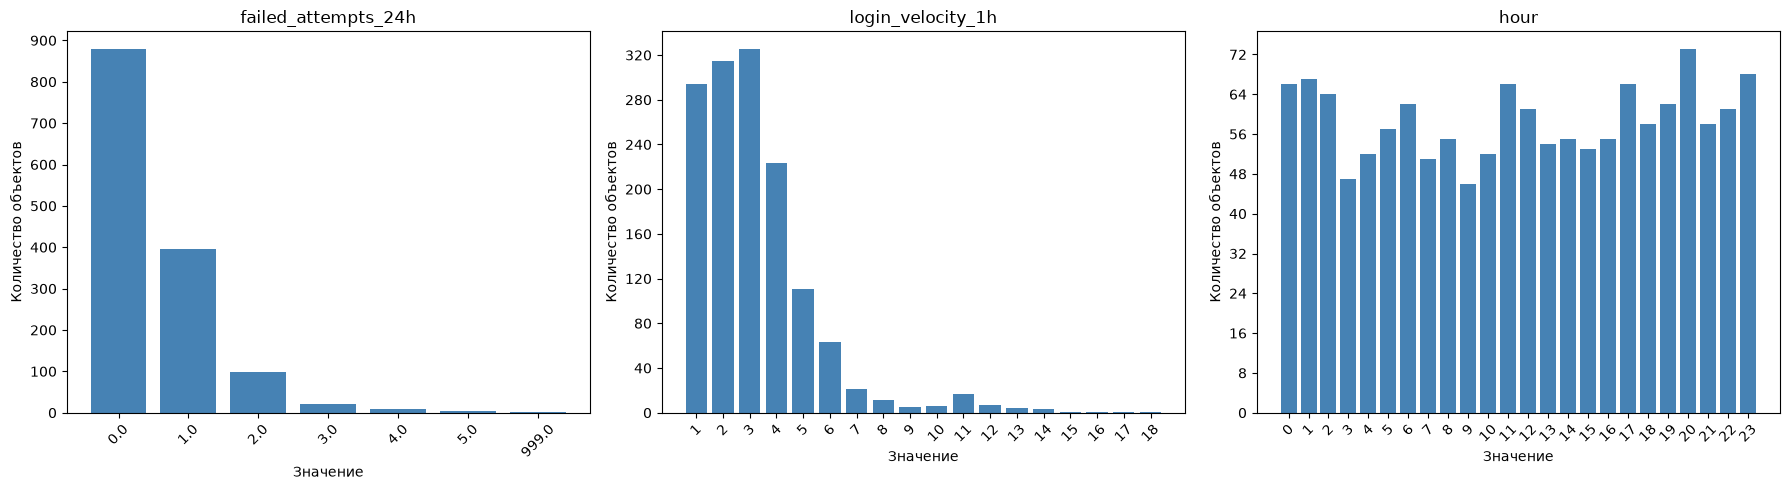

In [309]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator

# 1. Выбор трех числовых признаков
OUTLIER_COLS = [
    'failed_attempts_24h',
    'login_velocity_1h',
    'hour'
]

# Приведение к числовому формату
outl = df[OUTLIER_COLS].apply(pd.to_numeric, errors='coerce')

# 2. Квантили и поиск выбросов методом IQR
rows = []

for col in OUTLIER_COLS:
    s = outl[col].dropna()

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)

    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    # Отмечаем значения за границами IQR
    mask = (outl[col] < low) | (outl[col] > high)

    rows.append({
        'Признак': col,
        'Нижняя граница IQR': round(low, 2),
        'Верхняя граница IQR': round(high, 2),
        'Количество выбросов': int(mask.sum()),
        'Доля выбросов, %': round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(rows).set_index('Признак') # превращение списка словарей в таблицу, а также названия признаков = индексы строк
display(outlier_summary)

# 3. Построение гистограмм
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, OUTLIER_COLS):
    s = outl[col].dropna()

    # Если значения целочисленные — отдельный столбик для каждого значения
    if (s % 1 == 0).all() and s.nunique() <= 100:
        counts = s.value_counts().sort_index()

        ax.bar(
            counts.index.astype(str),
            counts.values,
            color='steelblue'
        )

        ax.tick_params(axis='x', rotation=45)

    else:
        # Для большого количества уникальных значений
        sns.histplot(s, bins=40, ax=ax, color='steelblue')

    ax.set_title(col)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Количество объектов') 
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))# знач. верт. оси - целые числа

plt.tight_layout() # авто. расположение
plt.show()

В признаке failed_attempts_24h обнаружено 34 выброса, что составляет 2,41% наблюдений. Верхняя граница IQR равна 2,5, поэтому значения от 3 и выше отмечаются как потенциальные выбросы. Они могут указывать на большое количество неудачных попыток входа и возможные попытки подбора пароля.

В признаке login_velocity_1h обнаружено 57 выбросов (4,04%). Верхняя граница IQR составляет 7. Повышенные значения могут свидетельствовать о необычно высокой интенсивности входов или автоматизированной активности.

В признаке hour выбросов по методу IQR не обнаружено. Нижняя граница составляет -14,5, а верхняя 37.5.

Таким образом, выбросы выявлены в двух из трёх исследуемых признаков.

**Правила обработки:**

1. failed_attempts_24h - значения 999 встречаются в очень небольшом количестве и, вероятно, являются ошибочными или специальными значениями. Поэтому для них выполним замену на NaN, чтобы не искажать анализ данных.
2. login_velocity_1h - значения выше верхней границы 7 будут сохранены, поскольку они могут отражать реальную подозрительную активность, например автоматизированные попытки входа или подбор пароля. Такие значения важно сохранить для дальнейшего анализа информационной безопасности.

Выполним замену значений 999 на NaN в признаке failed_attempts_24h:

In [310]:
# Считаем сколько значений 999 заменим на NaN
count = (df['failed_attempts_24h'] == 999).sum()

# Заменяем 999 на NaN
df.loc[df['failed_attempts_24h'] == 999, 'failed_attempts_24h'] = np.nan

print(f"Total replaced: {count}")

Total replaced: 2


Были выполнены две замены.

# 7. Дисбаланс целевой переменной

Посчитаем абсолютное число и долю объектов каждого класса:

In [311]:
# Количество объектов каждого класса
counts = df['is_suspicious'].value_counts().sort_index()

# Доля каждого класса в процентах
shares = df['is_suspicious'].value_counts(normalize=True).sort_index() * 100

# Таблица с результатами
class_stats = pd.DataFrame({
    'Количество объектов': counts,
    'Доля, %': shares.round(2)
})

class_stats.index = ['Обычные (0)', 'Подозрительные (1)']
display(class_stats)

,Количество объектов,"Доля, %"
Обычные (0),1283,91.06
Подозрительные (1),126,8.94


Далее построим столбчатую диаграмму распределения целевой переменной

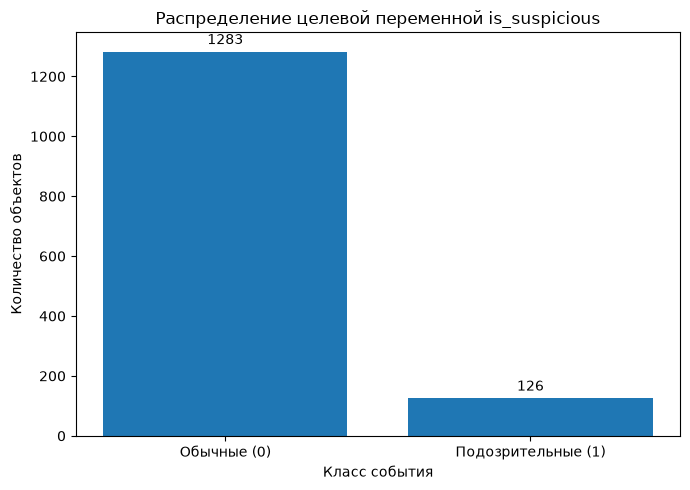

In [312]:
# Подписи классов
labels = ['Обычные (0)', 'Подозрительные (1)']

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, counts.values)

# Числовые подписи над столбцами
plt.bar_label(bars, fmt='%.0f', padding=3)

plt.title('Распределение целевой переменной is_suspicious')
plt.xlabel('Класс события')
plt.ylabel('Количество объектов')
plt.tight_layout()
plt.show()

В датасете представлены два класса: обычные события (is_suspicious = 0) и подозрительные события (is_suspicious = 1). Абсолютное число объектов и доля каждого класса рассчитаны и представлены в таблице и на столбчатой диаграмме.

Полученное распределение отражает соотношение обычных и подозрительных событий в имеющемся датасете. Однако оно не обязательно полностью соответствует реальной системе, поскольку данные могут быть специально отобраны или не отражать настоящую частоту атак.

Редким классом является is_suspicious = 1. Обычная accuracy может быть недостаточной метрикой, поскольку модель способна часто предсказывать преобладающий класс и получать высокую accuracy, одновременно пропуская значительную часть событий редкого класса.

# 8. Поиск потенциальной утечки данных

Для средства защиты в момент аутентификации известны все за исключением 2 столбцов и целевой переменной is_suspicious:
- analyst_verdict
- analyst_risk_score

Проверим, кодируют ли признаки analyst_verdict и analyst_risk_score целевую метку:

In [313]:
for col in ["analyst_verdict", "analyst_risk_score"]:
    print(f"\n--- {col} ---")

    table = pd.crosstab(df[col], df["is_suspicious"])
    display(table)

    accuracy = table.max(axis=1).sum() / table.to_numpy().sum() * 100

    print(f"Совпадение с целевой меткой: {accuracy:.2f}%")


--- analyst_verdict ---


is_suspicious,0,1
analyst_verdict,,
benign,1283,0
confirmed_threat,0,126


Совпадение с целевой меткой: 100.00%

--- analyst_risk_score ---


is_suspicious,0,1
analyst_risk_score,,
3,23,0
4,18,0
5,21,0
6,20,0
7,22,0
...,...,...
95,0,7
96,0,4
97,0,9


Совпадение с целевой меткой: 100.00%


Результаты показывают, что analyst_verdict и analyst_risk_score напрямую кодируют целевую метку. Это связано с тем, что их формирует аналитик после рассмотрения событий, поэтому их необходимо исключить из признаков.

Анализ риска запоминания объектов:

- Служебный идентификатор event_id стоит исключить из признаков, поскольку он идентифицируют отдельные события, а не описывает поведение пользователя. Модель может запоминать конкретные объекты вместо общих закономерностей.

- Время события (timestamp, hour, is_weekend). Исходный timestamp стоит исключить. hour и is_weekend можно сохранить, поскольку время суток и выходные дни могут влиять на характер активности.

- source_ip исключить, поскольку модель может запомнить конкретные IP-адреса, а не научиться распознавать общие признаки атаки. IP-адреса могут меняться, поэтому их полезность нужно оценивать на новых событиях.

- user_id исключить из базового набора признаков из-за риска запоминания конкретных пользователей.

Результаты последующей обработки analyst_verdict, analyst_risk_score необходимо исключить, так как они формируются после события, и это может привести к утечке информации из будущего.

Далее проверим, не могут ли полные дубликаты или связанные оказаться одновременно в train и test:

In [314]:
duplicates = df.duplicated().sum()

print(f"Количество полных дубликатов: {duplicates}")

user_counts = df['user_id'].value_counts()

print("Всего пользователей:", df['user_id'].nunique())
print("Пользователей с несколькими событиями:", (user_counts > 1).sum())

Количество полных дубликатов: 0
Всего пользователей: 120
Пользователей с несколькими событиями: 120


Полные дубликаты строк не обнаружены. При этом все 120 пользователей имеют несколько событий. Если случайно разделить данные на обучающую и тестовую выборки, события одного пользователя могут оказаться в обеих выборках, что создаст зависимость между ними и может завысить оценку качества модели. Поэтому при разделении следует учитывать группировку по user_id или временной порядок событий, в зависимости от сценария применения модели. Это позволит избежать попадания связанных объектов в обе выборки и получить более достоверную оценку качества модели.

Составим реестр полей:

In [315]:
from IPython.display import display

registry_data = [
    # Идентификаторы и служебные поля
    ("event_id", "в момент события", "технический идентификатор",
     "исключить из X",
     "Уникальный ключ записи, не описывает поведение пользователя"),

    ("user_id", "в момент события", "идентификатор пользователя",
     "исключить из X",
     "Модель может запоминать конкретных пользователей"),

    # Временное разделение
    ("timestamp", "в момент события", "временной признак и критерий разделения",
     "исключить из X",
     "Используется для разделения train/test по времени; абсолютное время может привести к запоминанию"),

    # Целевая переменная и потенциальная утечка
    ("analyst_verdict", "вероятно, после расследования", "возможная прямая утечка метки",
     "исключить из X",
     "Содержит итоговый вердикт аналитика"),

    ("analyst_risk_score", "зависит от способа расчёта", "возможная утечка из будущего",
     "исключить из X",
     "Рассчитывается после события, недоступен в момент принятия решения"),

    ("is_suspicious", "итоговая разметка", "целевая переменная",
     "использовать как y",
     "Метка, которую должна предсказывать модель"),

    # Временные признаки
    ("hour", "в момент события", "временной признак",
     "включить в X",
     "Позволяет выявлять закономерности по часу суток"),

    ("is_weekend", "в момент события", "временной признак",
     "включить в X",
     "Позволяет учитывать различия между буднями и выходными"),

    # Характеристики устройства
    ("device_type", "в момент события", "характеристика устройства",
     "включить в X",
     "Описывает тип используемого устройства"),

    ("os_family", "в момент события", "характеристика операционной системы",
     "включить в X",
     "Описывает операционную систему устройства"),

    ("browser_family", "в момент события", "характеристика браузера",
     "включить в X",
     "Описывает браузер, используемый при входе"),

    ("known_device", "в момент события, по предыдущей истории", "признак истории устройства",
     "включить в X",
     "Помогает определить, использовалось ли устройство ранее"),

    # Профиль пользователя и способ аутентификации
    ("department", "до события", "профиль пользователя",
     "включить в X",
     "Позволяет учитывать особенности подразделения пользователя"),

    ("auth_method", "в момент события", "метод аутентификации",
     "включить в X",
     "Позволяет учитывать способ подтверждения входа"),

    # История попыток входа
    ("failed_attempts_24h", "в момент события, по предыдущим событиям", "счётчик попыток",
     "включить в X",
     "Большое число неудачных попыток может указывать на подозрительную активность"),

    ("login_velocity_1h", "в момент события, по предыдущим событиям", "интенсивность входов",
     "включить в X",
     "Помогает выявлять необычно частые входы"),

    # Возраст учётной записи и пароля
    ("account_age_days", "до события", "возраст учётной записи",
     "включить в X",
     "Позволяет учитывать возраст учётной записи"),

    ("password_age_days", "до события", "возраст пароля",
     "включить в X",
     "Позволяет учитывать время с момента изменения пароля; неизвестные значения нужно обработать"),

    # Источник и география подключения
    ("source_ip", "в момент события", "сетевой идентификатор источника",
     "исключить из X",
     "Может привести к запоминанию конкретных IP-адресов"),

    ("country", "в момент события", "географический признак",
     "включить в X",
     "Позволяет учитывать страну, из которой выполнен вход"),

    ("distance_from_usual_km", "в момент события, при наличии истории", "географический признак",
     "включить в X",
     "Большое расстояние от обычного места подключения может указывать на необычную активность"),

    ("new_country", "в момент события, по предыдущей истории", "географический признак",
     "включить в X",
     "Показывает, выполнялся ли вход из новой для пользователя страны"),

    ("vpn_used", "в момент события", "признак источника подключения",
     "включить в X",
     "Позволяет учитывать использование VPN при подключении"),
]

registry_df = pd.DataFrame(
    registry_data,
    columns=[
        "Поле",
        "Момент появления",
        "Тип риска",
        "Решение",
        "Обоснование"
    ]
)

display(registry_df)

print(
    "\nПризнаков, включаемых в X:",
    sum(r[3].startswith("включить в X") for r in registry_data)
)

print(
    "Полей, исключаемых из X:",
    sum("исключить из X" in r[3] for r in registry_data)
)

,Поле,Момент появления,Тип риска,Решение,Обоснование
0,event_id,в момент события,технический идентификатор,исключить из X,"Уникальный ключ записи, не описывает поведение..."
1,user_id,в момент события,идентификатор пользователя,исключить из X,Модель может запоминать конкретных пользователей
2,timestamp,в момент события,временной признак и критерий разделения,исключить из X,Используется для разделения train/test по врем...
3,analyst_verdict,"вероятно, после расследования",возможная прямая утечка метки,исключить из X,Содержит итоговый вердикт аналитика
4,analyst_risk_score,зависит от способа расчёта,возможная утечка из будущего,исключить из X,"Рассчитывается после события, недоступен в мом..."
5,is_suspicious,итоговая разметка,целевая переменная,использовать как y,"Метка, которую должна предсказывать модель"
6,hour,в момент события,временной признак,включить в X,Позволяет выявлять закономерности по часу суток
7,is_weekend,в момент события,временной признак,включить в X,Позволяет учитывать различия между буднями и в...
8,device_type,в момент события,характеристика устройства,включить в X,Описывает тип используемого устройства
9,os_family,в момент события,характеристика операционной системы,включить в X,Описывает операционную систему устройства



Признаков, включаемых в X: 16
Полей, исключаемых из X: 6


# 9. Выбор и выполнение разделения

Выполним разделение:

In [316]:
# 1. Отделение X от y и удаление признаков утечки
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')

# Удаляем строки, у которых отсутствует время события
df = df.dropna(subset=['timestamp']).copy()

# Целевая переменная
y = df['is_suspicious']

# Признаки, которые не должны передаваться модели
exclude_cols = [
    'analyst_verdict',
    'analyst_risk_score',
    'event_id',
    'user_id',
    'timestamp',
    'source_ip',
    'is_suspicious'  # целевая переменная, не включаем в X
]

# Автоматически выбираем все остальные признаки
feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

X = df[feature_cols]

print("Признаки, включённые в X:")
print(feature_cols)
print("\nКоличество признаков:", len(feature_cols))


# 2. Временное разделение 80/20
# Сортируем индексы по времени события
sorted_idx = df.sort_values('timestamp').index

split_pos = int(len(sorted_idx) * 0.8)

train_idx = sorted_idx[:split_pos]
test_idx = sorted_idx[split_pos:]

X_train = X.loc[train_idx]
X_test = X.loc[test_idx]

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

print(f"\nX_train: {X_train.shape[0]} строк")
print(f"X_test:  {X_test.shape[0]} строк")


# 3. Проверка временного разделения
max_train_time = df.loc[train_idx, 'timestamp'].max()
min_test_time = df.loc[test_idx, 'timestamp'].min()

print("\nМаксимальное время train:", max_train_time)
print("Минимальное время test:", min_test_time)

assert max_train_time <= min_test_time, \
    "Ошибка: временной порядок нарушен!"

print("Проверка пройдена: train не позже test")


# 4. Сравнение распределения целевой переменной y
train_dist = y_train.value_counts(normalize=True).sort_index()
test_dist = y_test.value_counts(normalize=True).sort_index()

compare_df = pd.DataFrame({
    'train (кол-во)': y_train.value_counts().sort_index(),
    'train (%)': (train_dist * 100).round(2),
    'test (кол-во)': y_test.value_counts().sort_index(),
    'test (%)': (test_dist * 100).round(2)
}).fillna(0)

display(compare_df)

Признаки, включённые в X:
['department', 'country', 'device_type', 'os_family', 'browser_family', 'auth_method', 'hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h', 'distance_from_usual_km', 'account_age_days', 'password_age_days', 'known_device', 'new_country', 'vpn_used']

Количество признаков: 16

X_train: 1127 строк
X_test:  282 строк

Максимальное время train: 2026-03-14 02:38:48
Минимальное время test: 2026-03-14 03:15:47
Проверка пройдена: train не позже test


,train (кол-во),train (%),test (кол-во),test (%)
is_suspicious,,,,
0,1047,92.9,236,83.69
1,80,7.1,46,16.31


**1. Отделение признаков и исключение утечек**

Целевая переменная (y) определена как столбец is_suspicious, который указывает, является ли событие подозрительным.

В матрицу признаков (X) включены все доступные признаки, кроме служебных полей, идентификаторов, временной метки и потенциальных источников утечки. Всего в (X) включено 16 признаков. Из признаков исключены event_id, user_id, timestamp, source_ip, analyst_verdict и analyst_risk_score.

**2. Сравнение схем разделения**

Стратифицированная случайная: сохраняет приблизительные пропорции классов, но события одного пользователя могут попасть одновременно в train и test.

Групповая по user_id: исключает пересечение пользователей между выборками и позволяет оценить работу модели на новых пользователях.

Временная по timestamp: использует более ранние события для обучения, а более поздние – для тестирования. При этом один и тот же пользователь может присутствовать в обеих выборках.

**3. Выбор основной схемы**

Для данного варианта выбрана временная схема разделения по timestamp в соотношении приблизительно 80/20.

События были отсортированы по времени. Первые 80% объектов использованы для обучающей выборки train, а последние 20% – для тестовой выборки test.

В результате получены следующие размеры выборок:

- train – 1127 объектов;
- test – 282 объекта.

Такое разделение соответствует условиям применения модели в реальной системе информационной безопасности: модель обучается на ранее произошедших событиях, а затем анализирует новые события. Временная схема позволяет проверить, насколько хорошо модель выявляет подозрительную активность в более поздний период.

**4. Проверка корректности временного разделения**

Корректность разделения проверена сравнением максимального времени события в train и минимального времени события в test.

- Максимальное время в train: 2026-03-14 02:38:48;
- Минимальное время в test: 2026-03-14 03:15:47.

Условие корректности – максимальное время в train должно быть не позже минимального времени в test. В коде оно проверено с помощью утверждения assert max_train_time <= min_test_time.

Проверка пройдена успешно: последнее событие обучающей выборки произошло раньше первого события тестовой выборки. Следовательно, временной порядок разделения соблюдён.

**5. Сравнение распределения целевой переменной**

В обучающей выборке train содержится 1127 объектов. Из них 1047 (92,9%) относятся к классу 0 – неподозрительным событиям, а 80 (7,1%) – к классу 1, то есть подозрительным событиям.

В тестовой выборке test содержится 282 объекта. Из них 236 (83,69%) относятся к классу 0, а 46 (16,31%) – к классу 1.

Таким образом, доля подозрительных событий в тестовой выборке более чем в два раза выше, чем в обучающей. Это может быть связано с временным разделением данных: в более поздний период частота подозрительных событий могла увеличиться. В отличие от случайного разделения, временное не гарантирует сохранения пропорций классов. Поэтому различие необходимо учитывать при оценке качества модели, поскольку оно может повлиять на полученные метрики.

**Итог**

Для построения модели сформирована матрица (X), включающая 16 признаков, а целевая переменная (y) определена как is_suspicious. Идентификаторы, временная метка, IP-адрес и потенциальные источники утечки исключены из входных признаков.

Данные разделены по времени на обучающую выборку из 1127 объектов и тестовую выборку из 282 объектов. Проверка подтвердила соблюдение хронологического порядка.

# 10. Построение preprocessing pipeline

Выполним построение preprocessing pipeline:

In [317]:
from sklearn.compose import ColumnTransformer # назначает разную обработку разным столбцам
from sklearn.pipeline import Pipeline # соединяет несколько шагов обработки в одну последовательность
from sklearn.impute import SimpleImputer # Заполняет пропущенные значения
from sklearn.preprocessing import OneHotEncoder, RobustScaler # 1.Преобразует категории в числовые столбцы, 2.Масштабирование

# 1. Разделяем признаки по типам
numeric_features = [
    'hour',
    'is_weekend',
    'failed_attempts_24h',
    'login_velocity_1h',
    'distance_from_usual_km',
    'account_age_days',
    'password_age_days',
    'known_device',
    'new_country',
    'vpn_used'
]

categorical_features = [
    'department',
    'country',
    'device_type',
    'os_family',
    'browser_family',
    'auth_method'
]

# 2. Проверяем, что все признаки распределены по группам
assert set(numeric_features).isdisjoint(categorical_features)
assert set(numeric_features + categorical_features) == set(X_train.columns)

# 3. Обработка числовых признаков: пропуски = медиана, затем масштабирование
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# 4. Обработка категориальных признаков: пропуски = категория Unknown, затем One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# 5. Объединяем обработку в ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 6. Создаём общий Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])

# 7. Обучаем обработку только на Train
X_train_ready = pipeline.fit_transform(X_train)

# 8. Test только преобразуем - не обучаем на нём обработку
X_test_ready = pipeline.transform(X_test)

**1. Разделение признаков**

Числовые признаки: hour, is_weekend, failed_attempts_24h, login_velocity_1h, distance_from_usual_km, account_age_days, password_age_days, known_device, new_country, vpn_used.

Категориальные признаки: department, country, device_type, os_family, browser_family, auth_method.

Целевой признак: is_suspicious.

Поля event_id, user_id, timestamp, source_ip, analyst_verdict и analyst_risk_score исключены из входных признаков. event_id и user_id являются идентификаторами, timestamp используется для временного разделения данных, source_ip исключён как идентификатор с высокой уникальностью, а analyst_verdict и analyst_risk_score могут содержать информацию, недоступную в момент принятия решения.

**2. Обработка числовых признаков**

Пропуски заполняются медианой с помощью SimpleImputer(strategy='median'). Медиана устойчива к экстремальным значениям.

Для масштабирования используется RobustScaler, который использует медиану и межквартильный размах и поэтому менее чувствителен к выбросам. Это подходит для данных информационной безопасности, где могут встречаться аномально большие значения, например количество неудачных попыток входа или расстояние от обычного места входа.

**3. Обработка категориальных признаков**

Пропуски заменяются отдельной категорией Unknown с помощью SimpleImputer(strategy='constant', fill_value='Unknown').

Для кодирования категорий используется OneHotEncoder(handle_unknown='ignore'). Категориальные значения преобразуются в бинарные признаки. Если в тестовой выборке встретится категория, отсутствующая в обучающей, ошибка не возникнет.

**4. Сборка Pipeline**

ColumnTransformer позволяет применять разные преобразования к числовым и категориальным признакам. Для каждой группы создаётся отдельный Pipeline, после чего оба преобразования объединяются в общий Pipeline.

**5. Применение к данным**

Для обучающей выборки X_train применяется fit_transform(): вычисляются параметры предобработки и преобразуются данные.

Для тестовой выборки X_test применяется только transform(). Используются параметры, полученные на обучающей выборке. Это предотвращает утечку данных из тестовой выборки в процесс обучения предобработки.

# 11. Проверка результата преобразования

Выполним проверку результата преобразования:

In [318]:
import numpy as np
import joblib
from pathlib import Path

# 1. Проверяем размеры обработанных выборок
print("X_train_ready:", X_train_ready.shape)
print("X_test_ready:", X_test_ready.shape)

# 2. Проверяем соответствие количества строк целевым переменным
assert X_train_ready.shape[0] == len(y_train)
assert X_test_ready.shape[0] == len(y_test)

print("Количество строк совпадает с y_train и y_test")

# 3. Проверяем отсутствие NaN и бесконечных значений
print("NaN в train:", np.isnan(X_train_ready).sum())
print("NaN в test:", np.isnan(X_test_ready).sum())

print("Бесконечности в train:", np.isinf(X_train_ready).sum())
print("Бесконечности в test:", np.isinf(X_test_ready).sum())

assert np.isfinite(X_train_ready).all(), "В X_train_ready есть NaN или бесконечности"
assert np.isfinite(X_test_ready).all(), "В X_test_ready есть NaN или бесконечности"

print("Проверка NaN и бесконечностей пройдена")

# 4. Получаем названия результирующих признаков
feature_names = pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

print("Количество результирующих признаков:", len(feature_names))
print("Названия признаков:")
print(feature_names)

# 5. Проверяем, что число названий совпадает с числом столбцов
assert len(feature_names) == X_train_ready.shape[1]
assert len(feature_names) == X_test_ready.shape[1]

print("Количество признаков проверено")

# 6. Сохраняем Pipeline
Path("artifacts").mkdir(parents=True, exist_ok=True)

joblib.dump(
    pipeline,
    "artifacts/preprocessor.joblib"
)

print("Pipeline сохранён в artifacts/preprocessor.joblib")

X_train_ready: (1127, 45)
X_test_ready: (282, 45)
Количество строк совпадает с y_train и y_test
NaN в train: 0
NaN в test: 0
Бесконечности в train: 0
Бесконечности в test: 0
Проверка NaN и бесконечностей пройдена
Количество результирующих признаков: 45
Названия признаков:
['num__hour' 'num__is_weekend' 'num__failed_attempts_24h'
 'num__login_velocity_1h' 'num__distance_from_usual_km'
 'num__account_age_days' 'num__password_age_days' 'num__known_device'
 'num__new_country' 'num__vpn_used' 'cat__department_Unknown'
 'cat__department_finance' 'cat__department_hr' 'cat__department_it'
 'cat__department_operations' 'cat__department_r&d'
 'cat__department_sales' 'cat__department_soc' 'cat__country_BR'
 'cat__country_CN' 'cat__country_DE' 'cat__country_NL' 'cat__country_NO'
 'cat__country_PL' 'cat__country_RU' 'cat__country_SE' 'cat__country_US'
 'cat__device_type_desktop' 'cat__device_type_laptop'
 'cat__device_type_mobile' 'cat__device_type_tablet'
 'cat__os_family_Android' 'cat__os_family_

После предобработки размер обучающей выборки X_train_ready составил 1127 строк и 45 признаков, а тестовой выборки X_test_ready – 282 строки и 45 признаков. Количество строк совпадает с количеством объектов в y_train и y_test.

С помощью метода get_feature_names_out() получены названия всех 45 результирующих признаков. Увеличение числа признаков с 16 до 45 связано с применением One-Hot Encoding к категориальным признакам.

Дополнительно проверено отсутствие недопустимых значений: количество NaN и бесконечностей в обеих выборках равно нулю. Все проверки пройдены успешно.

Обученный Pipeline сохранён в файл artifacts/preprocessor.joblib для последующего повторного использования.

Корректность порядка обработки обеспечивается тем, что разделение данных выполняется до обучения Pipeline, fit_transform() применяется только к X_train, а для X_test используется исключительно transform(). Это предотвращает утечку информации из тестовой выборки при обучении параметров предобработки.

# 12. Итоговый аудит и выводы

## 12.1. Итоговая таблица аудита данных

In [319]:
from IPython.display import HTML, display

data = [
    {
        "Обнаруженная проблема": "Отрицательные значения в числовых признаках, где они недопустимы",
        "Количественная оценка": "Найдено 10",
        "Принятое решение": "Замена недопустимых значений на NaN",
        "Число затронутых объектов": "10",
        "Возможное влияние на модель": "Некорректные значения могут исказить закономерности, изучаемые моделью"
    },
	{
        "Обнаруженная проблема": "Пропущенные значения в числовых признаках",
        "Количественная оценка": "141 пропуск",
        "Принятое решение": "Замена медианой на этапе предобработки",
        "Число затронутых объектов": "141",
        "Возможное влияние на модель": "Без обработки модель может не принять данные или хуже распознавать угрозы"
    },
    {
        "Обнаруженная проблема": "Пропуски или неизвестные значения в категориальных признаках",
        "Количественная оценка": "62 пропусков",
        "Принятое решение": "Заполнение значением Unknown",
        "Число затронутых объектов": "62",
        "Возможное влияние на модель": "Необработанные значения могут привести к ошибкам или потере информации"
    },
    {
        "Обнаруженная проблема": "Возраст пароля превышает возраст учётной записи",
        "Количественная оценка": "Найдено 90 случаев",
        "Принятое решение": "Замена противоречивых значений на NaN",
        "Число затронутых объектов": "90",
        "Возможное влияние на модель": "Модель может обучиться на логически невозможных данных"
    },
    {
        "Обнаруженная проблема": "Некорректные даты",
        "Количественная оценка": "3 некорректные даты",
        "Принятое решение": "Удаление 3 строк с некорректными датами",
        "Число затронутых объектов": "3",
        "Возможное влияние на модель": "Модель может обучиться на несуществующих датах"        
    },
    {
        "Обнаруженная проблема": "Дубликаты строк или событий",
        "Количественная оценка": "18 полных дубликатов; 18 повторных event_id",
        "Принятое решение": "Проверить и удалить только подтверждённые дубликаты",
        "Число затронутых объектов": "18",
        "Возможное влияние на модель": "Повторяющиеся записи могут искусственно повысить качество модели"
    },
	{
        "Обнаруженная проблема": "Возможная утечка целевой информации",
        "Количественная оценка": "Исключены analyst_verdict, analyst_risk_score и is_suspicious",
        "Принятое решение": "Не использовать целевую переменную и признаки, основанные на последующей оценке аналитика",
        "Число затронутых объектов": "3 поля исключены из набора признаков",
        "Возможное влияние на модель": "Результаты могут выглядеть лучше реальных, если модель получает информацию, недоступную в момент решения"
    },
	{
		"Обнаруженная проблема": "Выбросы failed_attempts_24h и login_velocity_1h",
        "Количественная оценка": "34 значения по правилу IQR (2,41%) в failed_attempts_24h и 57 значений по правилу IQR (4,05%) в login_velocity_1h",
        "Принятое решение": "Заменить 2 найденых значения '999' у failed_attempts_24h; в login_velocity_1h значения не удалять и не обрезать",
        "Число затронутых объектов": "2",
        "Возможное влияние на модель": "Редкие значения у failed_attempts_24h могут отражать реальную подозрительную активность; значения login_velocity_1h демонстрируют, вероятно, высокую скорость входов, что может быть признаком атаки"
	},
    {
        "Обнаруженная проблема": "Дисбаланс классов",
        "Количественная оценка": "1283 объекта класса 0 (91,06%) и 126 объектов класса 1 (8,94%)",
        "Принятое решение": "Сохранить исходное распределение; учитывать дисбаланс при оценке",
        "Число затронутых объектов": "Все 1409 строк",
        "Возможное влияние на модель": "Accuracy может быть недостаточно информативной, поэтому необходимо использовать другие метрики"
    }
]

df_problems = pd.DataFrame(data)

display(HTML(
    df_problems.to_html(
        index=False,
        escape=False,
        border=1
    ).replace(
        '<table border="1" class="dataframe">',
        '<table style="border-collapse: collapse; width: 100%; '
        'font-size: 13px; table-layout: fixed;" border="1">'
    ).replace(
        '<th>',
        '<th style="padding: 8px; background-color: #e8eef5; '
        'text-align: left; overflow-wrap: anywhere;">'
    ).replace(
        '<td>',
        '<td style="padding: 8px; vertical-align: top; '
        'overflow-wrap: anywhere; white-space: normal;">'
    )
))

Обнаруженная проблема,Количественная оценка,Принятое решение,Число затронутых объектов,Возможное влияние на модель
"Отрицательные значения в числовых признаках, где они недопустимы",Найдено 10,Замена недопустимых значений на NaN,10,"Некорректные значения могут исказить закономерности, изучаемые моделью"
Пропущенные значения в числовых признаках,141 пропуск,Замена медианой на этапе предобработки,141,Без обработки модель может не принять данные или хуже распознавать угрозы
Пропуски или неизвестные значения в категориальных признаках,62 пропусков,Заполнение значением Unknown,62,Необработанные значения могут привести к ошибкам или потере информации
Возраст пароля превышает возраст учётной записи,Найдено 90 случаев,Замена противоречивых значений на NaN,90,Модель может обучиться на логически невозможных данных
Некорректные даты,3 некорректные даты,Удаление 3 строк с некорректными датами,3,Модель может обучиться на несуществующих датах
Дубликаты строк или событий,18 полных дубликатов; 18 повторных event_id,Проверить и удалить только подтверждённые дубликаты,18,Повторяющиеся записи могут искусственно повысить качество модели
Возможная утечка целевой информации,"Исключены analyst_verdict, analyst_risk_score и is_suspicious","Не использовать целевую переменную и признаки, основанные на последующей оценке аналитика",3 поля исключены из набора признаков,"Результаты могут выглядеть лучше реальных, если модель получает информацию, недоступную в момент решения"
Выбросы failed_attempts_24h и login_velocity_1h,"34 значения по правилу IQR (2,41%) в failed_attempts_24h и 57 значений по правилу IQR (4,05%) в login_velocity_1h",Заменить 2 найденых значения '999' у failed_attempts_24h; в login_velocity_1h значения не удалять и не обрезать,2,"Редкие значения у failed_attempts_24h могут отражать реальную подозрительную активность; значения login_velocity_1h демонстрируют, вероятно, высокую скорость входов, что может быть признаком атаки"
Дисбаланс классов,"1283 объекта класса 0 (91,06%) и 126 объектов класса 1 (8,94%)",Сохранить исходное распределение; учитывать дисбаланс при оценке,Все 1409 строк,"Accuracy может быть недостаточно информативной, поэтому необходимо использовать другие метрики"


## 12.2. Сравнение исходного и подготовленного датасетов

In [320]:
comparison = pd.DataFrame([
    {
        "Показатель": "Число объектов",
        "Исходный датасет": "1430",
        "Подготовленный датасет": "1409: 1127 в Train и 282 в Test"
    },
    {
        "Показатель": "Число признаков для модели",
        "Исходный датасет": "22 признака, исключая is_suspicious",
        "Подготовленный датасет": "16 исходных признаков преобразованы в 45"
    },
    {
        "Показатель": "Целевая переменная",
        "Исходный датасет": "is_suspicious",
        "Подготовленный датасет": "y_train и y_test"
    },
    {
        "Показатель": "Пропущенные значения",
        "Исходный датасет": (
            "141 пропуск в числовых признаках; "
            "62 в категориальных; "
            "90 противоречивых значений возраста пароля; "
            "10 недопустимых отрицательных значений"
        ),
        "Подготовленный датасет": "0 в X_train_ready и X_test_ready"
    },
    {
        "Показатель": "Полные дубликаты строк",
        "Исходный датасет": "18",
        "Подготовленный датасет": "0"
    },
    {
        "Показатель": "Доля класса 0 – обычное событие",
        "Исходный датасет": "1283 объекта (91,06%)",
        "Подготовленный датасет": (
            "Train: 1047 (92,9%); Test: 236 (83,69%)"
        )
    },
    {
        "Показатель": "Доля класса 1 – подозрительное событие",
        "Исходный датасет": "126 объектов (8,94%)",
        "Подготовленный датасет": (
            "Train: 80 (7,1%); Test: 46 (16,31%)"
        )
    }
])

display(comparison)

,Показатель,Исходный датасет,Подготовленный датасет
0,Число объектов,1430,1409: 1127 в Train и 282 в Test
1,Число признаков для модели,"22 признака, исключая is_suspicious",16 исходных признаков преобразованы в 45
2,Целевая переменная,is_suspicious,y_train и y_test
3,Пропущенные значения,141 пропуск в числовых признаках; 62 в категор...,0 в X_train_ready и X_test_ready
4,Полные дубликаты строк,18,0
5,Доля класса 0 – обычное событие,"1283 объекта (91,06%)","Train: 1047 (92,9%); Test: 236 (83,69%)"
6,Доля класса 1 – подозрительное событие,"126 объектов (8,94%)","Train: 80 (7,1%); Test: 46 (16,31%)"


## 12.3. Риски

### 1. Ошибки и проблемы в данных
**Описание:** В датасете есть пропуски, отрицательные значения и ошибки, например возраст пароля больше возраста учётной записи.

**Возможное влияние:** Из-за таких ошибок модель может неправильно определять подозрительные события.

**Меры контроля:**
- Проверять значения на ошибки и недопустимые диапазоны.
- Заменять некорректные значения на пропуски.
- Заполнять пропуски медианой или значением Unknown.

### 2. Утечка информации между выборками
**Описание:** Если неправильно разделить данные, похожие события могут попасть и в Train, и в Test. Также модель может получить признаки, которые стали известны только после события.

**Возможное влияние:** Модель покажет хороший результат на тесте, но хуже справится с новыми событиями.

**Меры контроля:**
- Разделять данные по времени: сначала Train, затем Test.
- Проверять, чтобы время событий в Train было раньше, чем в Test.
- Исключать analyst_verdict и analyst_risk_score, если они получены после события.

В данной работе временное разделение выполнено правильно: максимальное время Train – 2026-03-14 02:38:48, минимальное время Test – 2026-03-14 03:15:47. Пересечения по времени нет.

### 3. Отличие учебных данных от реальных условий
**Описание:** Учебный датасет может отличаться от реальной системы по поведению пользователей, способам входа и количеству атак.

**Возможное влияние:** В реальной работе модель может ошибаться чаще, чем на учебных данных.

**Меры контроля:**
- По возможности использовать данные из реальных журналов входа.
- Сравнивать учебные данные с данными реальной системы.
- Следить за изменением количества и типов подозрительных событий.

## 12.4. Итоговый вывод

В ходе лабораторной работы был проведён аудит и выполнена подготовка датасета событий аутентификации для последующей классификации подозрительных событий. Исходный датасет содержит 1430 объектов и 23 столбца, включая целевую переменную is_suspicious.

Для моделирования были исключены идентификаторы и признаки, которые могут приводить к утечке информации или нецелевому запоминанию данных. После разделения по времени сформированы обучающая выборка из 1127 объектов и тестовая выборка из 282 объектов. Временное пересечение между выборками отсутствует.

На этапе предобработки числовые признаки обрабатываются с помощью заполнения пропусков медианой и масштабирования RobustScaler, а категориальные признаки – заполнения неизвестных значений и кодирования OneHotEncoder. В результате получено 45 признаков. Проверка подтвердила отсутствие пропусков и бесконечностей в подготовленных матрицах.

Датасет можно считать предварительно пригодным для последующей лабораторной работы по классификации угроз, поскольку он содержит целевую переменную, разделён на Train и Test с учётом времени и подготовлен к обучению модели. При этом результаты необходимо интерпретировать с учётом дисбаланса классов, возможных ошибок исходных данных и ограниченного соответствия учебного набора реальным условиям информационной безопасности.